In [25]:
import pandas as pd
import numpy as np
df = pd.read_csv('data/raw/day_approach_maskedID_timeseries.csv')
df = df.replace(-0.01, np.nan)

feature_cols = ['total km', 'nr. sessions', 'km Z3-4', 'km Z5-T1-T2',
                'km sprinting', 'strength training', 'hours alternative',
                'perceived exertion', 'perceived trainingSuccess',
                'perceived recovery']
feature_stats = []
for feature in feature_cols:
    cols = [feature]
    cols += [f"{feature}.{i}" for i in range(1, 7)]
    feature_stats.append( df[cols].agg(['max', 'mean', 'std', 'count'], axis=1).add_prefix(f"{feature}_") )
X = pd.concat(feature_stats, axis=1)

print(X.shape)
print(X.describe())

(42766, 40)
       total km_max  total km_mean  total km_std  total km_count  \
count  42766.000000   42766.000000  42766.000000         42766.0   
mean      13.853192       7.041486      5.039410             7.0   
std        8.486734       5.197299      2.859534             0.0   
min        0.000000       0.000000      0.000000             7.0   
25%        9.000000       3.242857      3.454035             7.0   
50%       13.400000       6.371429      5.126634             7.0   
75%       18.200000       9.985714      6.632352             7.0   
max       57.000000      31.471429     25.975492             7.0   

       nr. sessions_max  nr. sessions_mean  nr. sessions_std  \
count      42766.000000       42766.000000      42766.000000   
mean           1.321166           0.829264          0.447148   
std            0.569865           0.355146          0.214427   
min            0.000000           0.000000          0.000000   
25%            1.000000           0.714286          0.3

In [26]:
y = df['injury']
groups = df['Athlete ID']
print(y.shape)
print(groups.shape)
X.index.equals(y.index)
X.index.equals(groups.index)
y.sum()


(42766,)
(42766,)


np.int64(583)

In [27]:

from pathlib import Path
from sklearn.model_selection import train_test_split

athlete_df = (df.groupby("Athlete ID", as_index=False)["injury"].sum()
                .rename(columns={"injury": "total_injuries"}))

print("Injury count distribution:")
print(athlete_df["total_injuries"].describe().round(1), "\n")

MIN_PER_BIN = 7
injured = athlete_df["total_injuries"] > 0
n_uninjured = (~injured).sum()

athlete_df["injury_bin"] = "uninjured"
athlete_df.loc[injured, "injury_bin"] = pd.qcut(
    athlete_df.loc[injured, "total_injuries"],
    q=3, labels=["low", "mid", "high"], duplicates="drop"
).astype(str)

if n_uninjured < MIN_PER_BIN:
    athlete_df.loc[~injured, "injury_bin"] = "low"
    print(f"Only {n_uninjured} uninjured athletes: merged into 'low'")

print("Athletes per bin:")
print(athlete_df["injury_bin"].value_counts())
print("\nInjury-count range per bin:")
print(athlete_df.groupby("injury_bin")["total_injuries"].agg(["min", "max"]))

assert athlete_df["injury_bin"].value_counts().min() >= 2, "a bin is too small to stratify"

dev_athletes, holdout_athletes = train_test_split(
    athlete_df, test_size=0.15,
    stratify=athlete_df["injury_bin"], random_state=42)

is_holdout = groups.isin(holdout_athletes["Athlete ID"])

print("\nHoldout check:")
print(f"  athletes:  {len(holdout_athletes)} of {len(athlete_df)} "
      f"({len(holdout_athletes) / len(athlete_df):.1%})")
print(f"  rows:      {is_holdout.mean():.1%}")
print(f"  injuries:  {y[is_holdout].sum() / y.sum():.1%}")
print(f"  injury rate  holdout: {y[is_holdout].mean():.2%}   dev: {y[~is_holdout].mean():.2%}")
print("  bins:", holdout_athletes["injury_bin"].value_counts().to_dict())

Path("data/splits").mkdir(parents=True, exist_ok=True)
(holdout_athletes[["Athlete ID"]].sort_values("Athlete ID")
    .to_csv("data/splits/holdout_athlete_ids.csv", index=False))

X_dev, y_dev, groups_dev = X[~is_holdout], y[~is_holdout], groups[~is_holdout]
assert X_dev.index.equals(y_dev.index) and X_dev.index.equals(groups_dev.index)
print(f"\nDev set: {X_dev.shape[0]} rows, {groups_dev.nunique()} athletes, {y_dev.sum()} injuries")

Injury count distribution:
count    74.0
mean      7.9
std       8.3
min       0.0
25%       2.0
50%       5.0
75%      11.5
max      35.0
Name: total_injuries, dtype: float64 

Athletes per bin:
injury_bin
low          22
high         21
mid          20
uninjured    11
Name: count, dtype: int64

Injury-count range per bin:
            min  max
injury_bin          
high         10   35
low           1    4
mid           5    9
uninjured     0    0

Holdout check:
  athletes:  12 of 74 (16.2%)
  rows:      15.9%
  injuries:  15.8%
  injury rate  holdout: 1.35%   dev: 1.36%
  bins: {'low': 4, 'mid': 3, 'high': 3, 'uninjured': 2}

Dev set: 35973 rows, 62 athletes, 491 injuries


In [28]:
import json
from datetime import datetime, timezone
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5
SEEDS = [0, 1, 2, 3, 4]
HOLDOUT_PATH = "data/splits/holdout_athlete_ids.csv"
CV_SPLITS_PATH = "data/splits/cv_splits.json"

assert dev_athletes["injury_bin"].value_counts().min() >= N_SPLITS, (
    f"Smallest dev bin has fewer than {N_SPLITS} athletes; increase MIN_PER_BIN or lower N_SPLITS."
)

dev_ids = dev_athletes["Athlete ID"].to_numpy()
dev_bins = dev_athletes["injury_bin"].to_numpy()

splits_by_seed = {}
for seed in SEEDS:
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
    splits_by_seed[str(seed)] = [
        sorted(dev_ids[val_idx].tolist())
        for _, val_idx in skf.split(dev_ids, dev_bins)
    ]

payload = {
    "metadata": {
        "holdout_file": HOLDOUT_PATH,
        "id_col": "Athlete ID",
        "stratify_col": "injury_bin",
        "split_strategy": "StratifiedKFold (athlete-level)",
        "n_splits": N_SPLITS,
        "n_dev_athletes": int(len(dev_athletes)),
        "n_dev_rows": int(len(X_dev)),
        "created_at": datetime.now(timezone.utc).isoformat(),
    },
    "seeds": splits_by_seed,
}

with open(CV_SPLITS_PATH, "w", encoding="utf-8") as f:
    json.dump(payload, f, indent=2)

print(f"Saved {len(SEEDS)}x{N_SPLITS} CV splits to {CV_SPLITS_PATH}")


Saved 5x5 CV splits to data/splits/cv_splits.json


In [29]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

with open(CV_SPLITS_PATH, encoding="utf-8") as f:
    cv = json.load(f)

holdout_set = set(pd.read_csv(HOLDOUT_PATH)["Athlete ID"].astype(int))
dev_set = set(groups_dev.unique().astype(int))

def evaluate(model, X, y, groups, cv, name=None, verbose=True):
    """Fit a fresh clone of `model` on every saved fold and score it.

    Returns one row per (seed, fold) with train/test AUC, test AP,
    the fold's injury rate, and AP lift (AP / injury rate).
    """
    name = name or type(model).__name__
    records = []
    t0 = time.time()

    for seed, folds in cv["seeds"].items():
        for k, test_ids in enumerate(folds):
            test_mask = groups.isin(test_ids).to_numpy()
            X_tr, y_tr = X[~test_mask], y[~test_mask]
            X_te, y_te = X[test_mask], y[test_mask]

            m = clone(model)
            m.fit(X_tr, y_tr)

            p_tr = m.predict_proba(X_tr)[:, 1]
            p_te = m.predict_proba(X_te)[:, 1]

            rate = y_te.mean()
            ap = average_precision_score(y_te, p_te)
            records.append({
                "model": name, "seed": int(seed), "fold": k,
                "train_auc": roc_auc_score(y_tr, p_tr),
                "test_auc": roc_auc_score(y_te, p_te),
                "test_ap": ap,
                "injury_rate": rate,
                "ap_lift": ap / rate,
            })

    results = pd.DataFrame(records)
    if verbose:
        s = summarize(results)
        print(f"{name}: test AUC {s['test_auc_mean']:.4f} ± {s['test_auc_std']:.4f} | "
              f"train AUC {s['train_auc_mean']:.4f} | "
              f"AP lift {s['ap_lift_mean']:.2f} ± {s['ap_lift_std']:.2f} | "
              f"{time.time() - t0:.0f}s")
    return results


def summarize(results):
    """Mean and std (ddof=1) of the main metrics across all folds."""
    out = {}
    for col in ["train_auc", "test_auc", "ap_lift"]:
        out[f"{col}_mean"] = results[col].mean()
        out[f"{col}_std"] = results[col].std()
    return out


def compare(results_a, results_b, metric="test_auc"):
    """Paired per-fold difference (b - a) on the same saved folds."""
    merged = results_a.merge(results_b, on=["seed", "fold"], suffixes=("_a", "_b"))
    diff = merged[f"{metric}_b"] - merged[f"{metric}_a"]
    print(f"{results_b['model'].iloc[0]} vs {results_a['model'].iloc[0]} ({metric}): "
          f"mean diff {diff.mean():+.4f}, b wins {int((diff > 0).sum())}/{len(diff)} folds")
    return diff

In [30]:
import xgboost as xgb
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

prevalence = DummyClassifier(strategy="prior")

logreg = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)

xgb_base = xgb.XGBClassifier(
    max_depth=2, n_estimators=512, learning_rate=0.01,
    random_state=0, n_jobs=-1,
)

res_prev = evaluate(prevalence, X_dev, y_dev, groups_dev, cv, name="prevalence")
res_lr   = evaluate(logreg,     X_dev, y_dev, groups_dev, cv, name="logreg")
res_xgb  = evaluate(xgb_base,   X_dev, y_dev, groups_dev, cv, name="xgb_d2")

compare(res_lr, res_xgb)

prevalence: test AUC 0.5000 ± 0.0000 | train AUC 0.5000 | AP lift 1.00 ± 0.00 | 0s
logreg: test AUC 0.6173 ± 0.0317 | train AUC 0.6746 | AP lift 1.43 ± 0.22 | 1s
xgb_d2: test AUC 0.6156 ± 0.0280 | train AUC 0.7485 | AP lift 1.51 ± 0.37 | 9s
xgb_d2 vs logreg (test_auc): mean diff -0.0017, b wins 10/25 folds


0     0.019145
1    -0.006865
2     0.028940
3    -0.012425
4     0.014001
5    -0.032568
6     0.005048
7    -0.035395
8    -0.010147
9     0.034251
10   -0.015212
11    0.031913
12   -0.002890
13   -0.004531
14   -0.036914
15    0.025934
16    0.000154
17   -0.005157
18    0.027087
19   -0.021095
20   -0.035046
21   -0.009671
22   -0.006134
23    0.017476
24   -0.012153
dtype: float64

In [72]:


MIN_PAST = 28        # rows of history required before a baseline counts
FLOOR_FRAC = 0.10    # std floor = 10% of the column's median nonzero past std
SPARSE_BASES = ['km sprinting', 'strength training', 'hours alternative']  # use differences, not z-scores

# Drop constant columns (e.g., count = 7 for load features)
constant_cols = X.columns[X.nunique(dropna=True) <= 1].tolist()
X_norm_input = X.drop(columns=constant_cols)
print("Dropped constant columns:", constant_cols)

# Sort by athlete, then date
sorted_idx = df.sort_values(['Athlete ID', 'Date']).index
X_sorted = X_norm_input.loc[sorted_idx]
ath_sorted = df.loc[sorted_idx, 'Athlete ID']
assert not df.duplicated(['Athlete ID', 'Date']).any(), "duplicate (athlete, date) rows"

grouped = X_sorted.groupby(ath_sorted, sort=False)

# Past-only baselines (current row excluded by shift)
past_mean = grouped.transform(lambda s: s.shift(1).expanding(min_periods=MIN_PAST).mean())
past_std  = grouped.transform(lambda s: s.shift(1).expanding(min_periods=MIN_PAST).std())

# Decide z-score vs difference per column
std_floor = past_std.where(past_std > 0).median() * FLOOR_FRAC   # nonzero stds only

is_sparse = X_sorted.columns.to_series().apply(
    lambda c: any(c.startswith(b + '_') for b in SPARSE_BASES))
bad_floor = std_floor.isna() | (std_floor <= 0)
diff_cols = X_sorted.columns[is_sparse | bad_floor]
z_cols    = X_sorted.columns.difference(diff_cols, sort=False)

print(f"\nz-score columns ({len(z_cols)}):", list(z_cols))
print(f"difference columns ({len(diff_cols)}):", list(diff_cols))

z_part = ((X_sorted[z_cols] - past_mean[z_cols])
          / past_std[z_cols].clip(lower=std_floor[z_cols], axis=1)).add_suffix('_z')
d_part = (X_sorted[diff_cols] - past_mean[diff_cols]).add_suffix('_diff')

X_norm = pd.concat([z_part, d_part], axis=1)

# Restore original row order and check alignment
X_norm = X_norm.loc[X.index]
assert X_norm.index.equals(X.index)
assert X_norm.index.equals(y.index)
assert X_norm.index.equals(groups.index)

n_inf = np.isinf(X_norm.to_numpy(dtype=float)).sum()
assert n_inf == 0, f"{n_inf} infinite values remain"

print("\nSummary (z columns should be centered near 0, std near 1):")
print(X_norm.describe().T[['count', 'mean', 'std', 'min', 'max']].round(2).to_string())

past_rows = grouped.cumcount().loc[X.index] # rows of history before each row
check = df.loc[42755:42765, ['Athlete ID', 'Date']].assign(
    past_rows=past_rows.loc[42755:42765],
    has_baseline=past_mean.loc[42755:42765].notna().any(axis=1))
print("\nRows 42755–42765:")
print(check.to_string())


a0 = ath_sorted.iloc[0]
rows_a0 = X_sorted[ath_sorted == a0]
col = 'total km_mean'
manual = rows_a0[col].iloc[:MIN_PAST].mean()
auto = past_mean.loc[rows_a0.index[MIN_PAST], col]
print(f"\nHand check ({col}, athlete {a0}, row {MIN_PAST + 1}): manual {manual:.4f} vs computed {auto:.4f}")
assert np.isclose(manual, auto)

Dropped constant columns: ['total km_count', 'nr. sessions_count', 'km Z3-4_count', 'km Z5-T1-T2_count', 'km sprinting_count', 'strength training_count', 'hours alternative_count']

z-score columns (24): ['total km_max', 'total km_mean', 'total km_std', 'nr. sessions_max', 'nr. sessions_mean', 'nr. sessions_std', 'km Z3-4_max', 'km Z3-4_mean', 'km Z3-4_std', 'km Z5-T1-T2_max', 'km Z5-T1-T2_mean', 'km Z5-T1-T2_std', 'perceived exertion_max', 'perceived exertion_mean', 'perceived exertion_std', 'perceived exertion_count', 'perceived trainingSuccess_max', 'perceived trainingSuccess_mean', 'perceived trainingSuccess_std', 'perceived trainingSuccess_count', 'perceived recovery_max', 'perceived recovery_mean', 'perceived recovery_std', 'perceived recovery_count']
difference columns (9): ['km sprinting_max', 'km sprinting_mean', 'km sprinting_std', 'strength training_max', 'strength training_mean', 'strength training_std', 'hours alternative_max', 'hours alternative_mean', 'hours alternative_

In [73]:

Z_CLIP = 10   # cap for z-scores

count_cols = [c for c in X_norm.columns if c.startswith('perceived') and '_count_' in c]

# Confirm they really are identical before dropping any
ref = X_norm[count_cols[0]]
identical = [c for c in count_cols[1:] if ref.equals(X_norm[c])]
print("Identical to", count_cols[0], ":", identical)

X_norm = (X_norm.drop(columns=identical)
                .rename(columns={count_cols[0]: 'n_rated_days_z'}))

z_cols = [c for c in X_norm.columns if c.endswith('_z')]
n_clipped = ((X_norm[z_cols].abs() > Z_CLIP) & X_norm[z_cols].notna()).sum()
X_norm[z_cols] = X_norm[z_cols].clip(lower=-Z_CLIP, upper=Z_CLIP)

print(f"\nValues clipped at ±{Z_CLIP} (columns with any):")
print(n_clipped[n_clipped > 0].sort_values(ascending=False).to_string())

assert X_norm.index.equals(X.index) and X_norm.index.equals(y.index)
assert not np.isinf(X_norm.to_numpy(dtype=float)).any()
print(f"\nX_norm: {X_norm.shape[1]} columns")
print(X_norm[z_cols if 'n_rated_days_z' not in z_cols else z_cols]
      .describe().T[['mean', 'std', 'min', 'max']].round(2).to_string())

Identical to perceived exertion_count_z : ['perceived trainingSuccess_count_z', 'perceived recovery_count_z']

Values clipped at ±10 (columns with any):
perceived trainingSuccess_mean_z    98
perceived trainingSuccess_max_z     94
perceived exertion_max_z            81
perceived recovery_max_z            81
perceived trainingSuccess_std_z     78
perceived exertion_mean_z           73
perceived exertion_std_z            65
perceived recovery_mean_z           63
perceived recovery_std_z            61
km Z5-T1-T2_std_z                   33
nr. sessions_max_z                  33
km Z5-T1-T2_max_z                   32
km Z5-T1-T2_mean_z                  28
km Z3-4_mean_z                      15
km Z3-4_std_z                       14
km Z3-4_max_z                       14
total km_max_z                       9
nr. sessions_std_z                   7
total km_std_z                       7
total km_mean_z                      6
n_rated_days_z                       3
nr. sessions_mean_z         

In [85]:

A = X_norm_input
B = X_norm
C = pd.concat([A, B], axis=1)
assert X_dev.index.equals(y_dev.index) and X_dev.index.equals(groups_dev.index)
print(f"\nDev set: {X_dev.shape[0]} rows, {groups_dev.nunique()} athletes, {y_dev.sum()} injuries")

HOLDOUT_PATH = "data/splits/holdout_athlete_ids.csv"

holdout_ids = set(pd.read_csv(HOLDOUT_PATH)["Athlete ID"].astype(int))
dev_mask = ~groups.isin(holdout_ids)

A_dev = A[dev_mask]
B_dev = B[dev_mask]
C_dev = C[dev_mask]
y_dev = y[dev_mask]
groups_dev = groups[dev_mask]

for name, tbl in [("A_dev", A_dev), ("B_dev", B_dev), ("C_dev", C_dev), ("groups_dev", groups_dev)]:
    assert tbl.index.equals(y_dev.index), f"{name} index doesn't match y_dev"

assert not set(groups_dev.unique()) & holdout_ids, "holdout athletes leaked into dev"
assert groups_dev.nunique() == 62, f"expected 62 dev athletes, got {groups_dev.nunique()}"
assert int(y_dev.sum()) == 491, f"expected 491 dev injuries, got {int(y_dev.sum())}"

print(f"Dev set: {len(y_dev)} rows, {groups_dev.nunique()} athletes, {int(y_dev.sum())} injuries")
print(f"A_dev {A_dev.shape} | B_dev {B_dev.shape} | C_dev {C_dev.shape}")

logreg = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
    LogisticRegression(max_iter=2000),
)

xgb_base = xgb.XGBClassifier(
    max_depth=2, n_estimators=512, learning_rate=0.01,
    random_state=0, n_jobs=-1,
)


A_lr_raw = evaluate(logreg,      A_dev, y_dev, groups_dev, cv, name="A_logreg")
A_lr_norm = evaluate(logreg,     B_dev, y_dev, groups_dev, cv, name="A_logregnorm")
A_lr_raw_norm = evaluate(logreg,     C_dev, y_dev, groups_dev, cv, name="A_logregraw+norm")
A_xgb_raw = evaluate(xgb_base,     A_dev, y_dev, groups_dev, cv, name="A_xgbraw")
A_xgb_norm = evaluate(xgb_base,     B_dev, y_dev, groups_dev, cv, name="A_xgbnorm")
A_xgb_raw_norm = evaluate(xgb_base,     C_dev, y_dev, groups_dev, cv, name="A_xgbraw+norm")

compare(A_lr_raw, A_lr_norm)
compare(A_xgb_raw, A_xgb_raw_norm)





Dev set: 35973 rows, 62 athletes, 491 injuries
Dev set: 35973 rows, 62 athletes, 491 injuries
A_dev (35973, 33) | B_dev (35973, 31) | C_dev (35973, 64)
A_logreg: test AUC 0.6173 ± 0.0317 | train AUC 0.6747 | AP lift 1.43 ± 0.22 | 1s
A_logregnorm: test AUC 0.6376 ± 0.0312 | train AUC 0.6870 | AP lift 2.69 ± 1.18 | 2s
A_logregraw+norm: test AUC 0.6318 ± 0.0355 | train AUC 0.7180 | AP lift 2.43 ± 0.93 | 3s
A_xgbraw: test AUC 0.6156 ± 0.0280 | train AUC 0.7485 | AP lift 1.51 ± 0.37 | 9s
A_xgbnorm: test AUC 0.6545 ± 0.0337 | train AUC 0.7784 | AP lift 2.85 ± 0.85 | 9s
A_xgbraw+norm: test AUC 0.6588 ± 0.0305 | train AUC 0.7929 | AP lift 3.01 ± 0.80 | 12s
A_logregnorm vs A_logreg (test_auc): mean diff +0.0203, b wins 20/25 folds
A_xgbraw+norm vs A_xgbraw (test_auc): mean diff +0.0432, b wins 24/25 folds


0     0.042504
1     0.077668
2    -0.010672
3     0.067641
4     0.017789
5     0.041680
6     0.024482
7     0.062630
8     0.005920
9     0.050727
10    0.085658
11    0.035583
12    0.025904
13    0.077519
14    0.033193
15    0.066845
16    0.009662
17    0.015914
18    0.018278
19    0.057805
20    0.052171
21    0.052248
22    0.070237
23    0.044031
24    0.055360
dtype: float64

In [86]:
import numpy as np
import pandas as pd

MIN_PAST = 28

# Rows of history before each row (aligned to X's index)
order = df.sort_values(['Athlete ID', 'Date']).index
past_rows = df.loc[order].groupby('Athlete ID').cumcount().loc[X.index]
pr_dev = past_rows[dev_mask]
assert pr_dev.index.equals(y_dev.index)

# Injury rate: early rows vs later rows (dev set)
early = pr_dev < MIN_PAST
print("Injury rate by position in the athlete's record (dev):")
print(f"  first {MIN_PAST} rows: {y_dev[early].mean():.2%}  "
      f"({int(y_dev[early].sum())} injuries / {int(early.sum())} rows)")
print(f"  later rows:     {y_dev[~early].mean():.2%}  "
      f"({int(y_dev[~early].sum())} injuries / {int((~early).sum())} rows)\n")

# Train and score only on rows that have a baseline
base = pr_dev >= MIN_PAST
A_b, C_b = A_dev[base], C_dev[base]
y_b, g_b = y_dev[base], groups_dev[base]

# NaNs left in the normalized columns are NOT timeline-related (e.g. std with <=2 rated days)
norm_cols = [c for c in C_b.columns if c.endswith(('_z', '_diff'))]
print(f"Baseline-only set: {len(y_b)} rows, {g_b.nunique()} athletes, {int(y_b.sum())} injuries")
print(f"Remaining NaN share in normalized columns: {C_b[norm_cols].isna().mean().mean():.2%}\n")

res_xgb_raw_b = evaluate(xgb_base, A_b, y_b, g_b, cv, name="xgb_raw [baseline rows]")
res_xgb_rn_b  = evaluate(xgb_base, C_b, y_b, g_b, cv, name="xgb_raw+norm [baseline rows]")

print()
d_auc = compare(res_xgb_raw_b, res_xgb_rn_b, "test_auc")
d_ap  = compare(res_xgb_raw_b, res_xgb_rn_b, "ap_lift")

Injury rate by position in the athlete's record (dev):
  first 28 rows: 1.27%  (22 injuries / 1736 rows)
  later rows:     1.37%  (469 injuries / 34237 rows)

Baseline-only set: 34237 rows, 62 athletes, 469 injuries
Remaining NaN share in normalized columns: 1.88%

xgb_raw [baseline rows]: test AUC 0.6115 ± 0.0294 | train AUC 0.7522 | AP lift 1.50 ± 0.38 | 9s
xgb_raw+norm [baseline rows]: test AUC 0.6565 ± 0.0316 | train AUC 0.7979 | AP lift 3.00 ± 0.86 | 12s

xgb_raw+norm [baseline rows] vs xgb_raw [baseline rows] (test_auc): mean diff +0.0449, b wins 23/25 folds
xgb_raw+norm [baseline rows] vs xgb_raw [baseline rows] (ap_lift): mean diff +1.4974, b wins 23/25 folds


In [102]:
import optuna
from optuna.visualization import (
    plot_contour,
    plot_optimization_history,
    plot_param_importances,
)

optuna.logging.set_verbosity(optuna.logging.WARNING)   # quiet per-trial logs

# ---------- Tuning folds: seed 0's 5 athlete folds only ----------
cv_tune = {"metadata": cv["metadata"], "seeds": {"0": cv["seeds"]["0"]}}

def make_xgb(params):
    return xgb.XGBClassifier(**params, random_state=0, n_jobs=-1)

def objective(trial):
    params = {
        "n_estimators":     trial.suggest_int("n_estimators", 100, 1000, step=50),
        "max_depth":        trial.suggest_int("max_depth", 1, 4),
        "learning_rate":    trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 200, log=True),
        "subsample":        trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_lambda":       trial.suggest_float("reg_lambda", 0.1, 50, log=True),
    }
    res = evaluate(make_xgb(params), C_dev, y_dev, groups_dev, cv_tune, verbose=False)
    trial.set_user_attr("train_auc", res["train_auc"].mean())
    trial.set_user_attr("ap_lift", res["ap_lift"].mean())
    return res["test_auc"].mean()

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=100, show_progress_bar=True)

# ---------- Look at the results ----------
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
trials = trials.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
trials["gap"] = trials["train_auc"] - trials["value"]
print("Top 10 trials (tuning folds only -- optimistic):")
print(trials.sort_values("value", ascending=False).head(10).round(4).to_string(index=False))

# ---------- Pick the simplest config within 0.01 of the best ----------
TOL = 0.01
near_best = trials[trials["value"] >= study.best_value - TOL]
chosen = near_best.sort_values(
    ["max_depth", "min_child_weight", "n_estimators"],
    ascending=[True, False, True]          # shallow, more regularized, fewer trees
).iloc[0]

param_names = ["n_estimators", "max_depth", "learning_rate", "min_child_weight",
               "subsample", "colsample_bytree", "reg_lambda"]
chosen_params = {p: chosen[p] for p in param_names}
chosen_params["n_estimators"] = int(chosen_params["n_estimators"])
chosen_params["max_depth"] = int(chosen_params["max_depth"])

print(f"\nBest tuning AUC: {study.best_value:.4f} | {len(near_best)} trials within {TOL}")
print("Chosen (simplest near-best):", {k: round(v, 4) if isinstance(v, float) else v
                                       for k, v in chosen_params.items()})

# ---------- Confirm on all 25 folds vs the current best ----------
res_tuned = evaluate(make_xgb(chosen_params), C_dev, y_dev, groups_dev, cv, name="xgb_tuned")
compare(A_xgb_raw_norm, res_tuned, "test_auc")
compare(A_xgb_raw_norm, res_tuned, "ap_lift")

  0%|          | 0/100 [00:00<?, ?it/s]

Top 10 trials (tuning folds only -- optimistic):
 number  value  colsample_bytree  learning_rate  max_depth  min_child_weight  n_estimators  reg_lambda  subsample  ap_lift  train_auc    gap
     66 0.6701            0.8714         0.0067          1            3.6498           450      0.3338     0.6587   3.3568     0.7226 0.0524
     52 0.6698            0.8827         0.0070          1            3.9574           550      0.3854     0.6338   3.1189     0.7276 0.0577
     83 0.6698            0.9661         0.0072          1            5.0891           600      0.1584     0.6583   3.1317     0.7300 0.0602
     75 0.6697            0.8993         0.0066          1            2.7168           500      0.1834     0.7023   3.5813     0.7254 0.0557
     74 0.6694            0.9470         0.0071          1            3.7245           450      0.2264     0.7119   3.3523     0.7235 0.0541
     62 0.6694            0.9702         0.0067          1            3.5058           550      0.1952   

0    -0.028577
1    -1.177226
2     0.493038
3    -0.684732
4    -0.626901
5     0.129067
6     0.523352
7    -1.545837
8    -0.045825
9     0.984738
10   -0.338077
11   -0.151669
12   -0.238301
13   -1.635320
14   -0.450229
15   -0.099066
16    3.527332
17   -1.742991
18    1.005258
19   -0.787319
20    0.547315
21   -0.428133
22   -0.352360
23   -0.799531
24   -0.667741
dtype: float64

/var/folders/46/rw6qkcrd5_dcm81sx5n2lqp80000gn/T/ipykernel_44600/2230250967.py:4: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


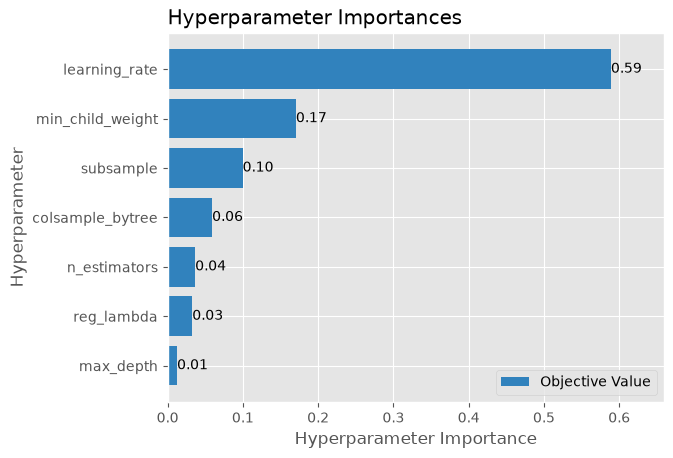

/var/folders/46/rw6qkcrd5_dcm81sx5n2lqp80000gn/T/ipykernel_44600/2230250967.py:6: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  plot_slice(study)


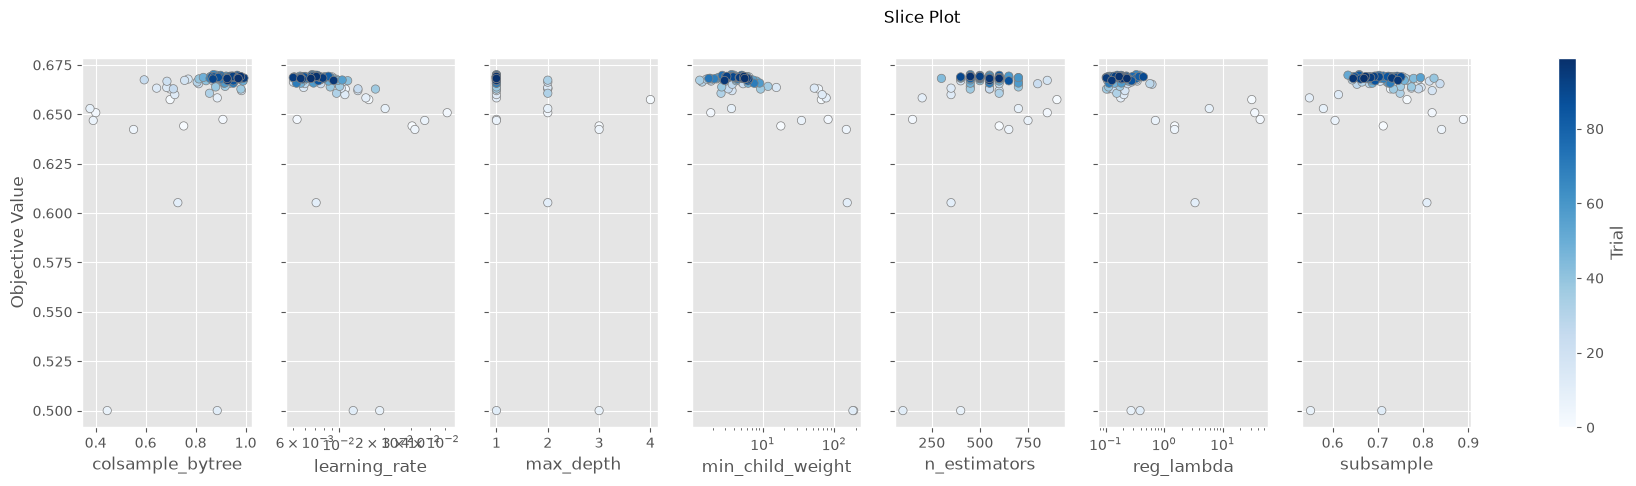

In [106]:
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import plot_param_importances, plot_slice

plot_param_importances(study)
plt.show()
plot_slice(study)
plt.show()

A_xgbraw_child: test AUC 0.6156 ± 0.0280 | train AUC 0.7485 | AP lift 1.51 ± 0.37 | 9s
A_xgbnorm_child: test AUC 0.6545 ± 0.0337 | train AUC 0.7784 | AP lift 2.85 ± 0.85 | 9s
A_xgbraw+norm_child: test AUC 0.6588 ± 0.0305 | train AUC 0.7929 | AP lift 3.01 ± 0.80 | 12s
